In [1]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename in [
            'baseline_metrics.csv',
            'grid_search_metrics.csv',
            'randomized_search_metrics.csv'
        ]:
            print(os.path.join(dirname, filename))


/kaggle/input/notebooks/ahmadlmomani/03-random-forest-grid-search/grid_search_results/grid_search_metrics.csv
/kaggle/input/notebooks/ahmadlmomani/notebook-04-randomizedsearchcv/randomized_search_results/randomized_search_metrics.csv
/kaggle/input/notebooks/ahmadlmomani/02-random-forest-baseline/baseline_results/baseline_metrics.csv


In [3]:

baseline_path = "/kaggle/input/notebooks/ahmadlmomani/02-random-forest-baseline/baseline_results/baseline_metrics.csv"

grid_path = "/kaggle/input/notebooks/ahmadlmomani/03-random-forest-grid-search/grid_search_results/grid_search_metrics.csv"

random_path = "/kaggle/input/notebooks/ahmadlmomani/notebook-04-randomizedsearchcv/randomized_search_results/randomized_search_metrics.csv"

baseline_df = pd.read_csv(baseline_path)
grid_df = pd.read_csv(grid_path)
random_df = pd.read_csv(random_path)

print("All results loaded successfully!")


All results loaded successfully!


In [4]:

# Combine results from the three models

comparison_df = pd.concat(
    [baseline_df, grid_df, random_df],
    ignore_index=True
)

print("Comparison DataFrame created successfully!")

display(comparison_df)


Comparison DataFrame created successfully!


,Model,Accuracy,Precision,Recall,F1-Score,Training Time,Prediction Time,Search Time,Best CV F1
0,Random Forest Baseline,0.722794,0.748023,0.625709,0.681420,0.832267,0.071302,NaN,NaN
1,Random Forest Grid Search,0.732647,0.766474,0.626654,0.689548,NaN,0.114934,142.529841,0.69344
2,Random Forest Randomized Search,0.732647,0.766474,0.626654,0.689548,NaN,0.105181,76.610195,0.69344


In [5]:

final_comparison = comparison_df[[
    'Model',
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score'
]].copy()

final_comparison['Execution Time (sec)'] = [
    baseline_df['Training Time'].iloc[0],
    grid_df['Search Time'].iloc[0],
    random_df['Search Time'].iloc[0]
]

display(final_comparison.round(4))



,Model,Accuracy,Precision,Recall,F1-Score,Execution Time (sec)
0,Random Forest Baseline,0.7228,0.7480,0.6257,0.6814,0.8323
1,Random Forest Grid Search,0.7326,0.7665,0.6267,0.6895,142.5298
2,Random Forest Randomized Search,0.7326,0.7665,0.6267,0.6895,76.6102


In [6]:

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

comparison_metrics = comparison_df[
    ['Model'] + metrics
].set_index('Model')

display(comparison_metrics)


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Random Forest Baseline,0.722794,0.748023,0.625709,0.681420
Random Forest Grid Search,0.732647,0.766474,0.626654,0.689548
Random Forest Randomized Search,0.732647,0.766474,0.626654,0.689548


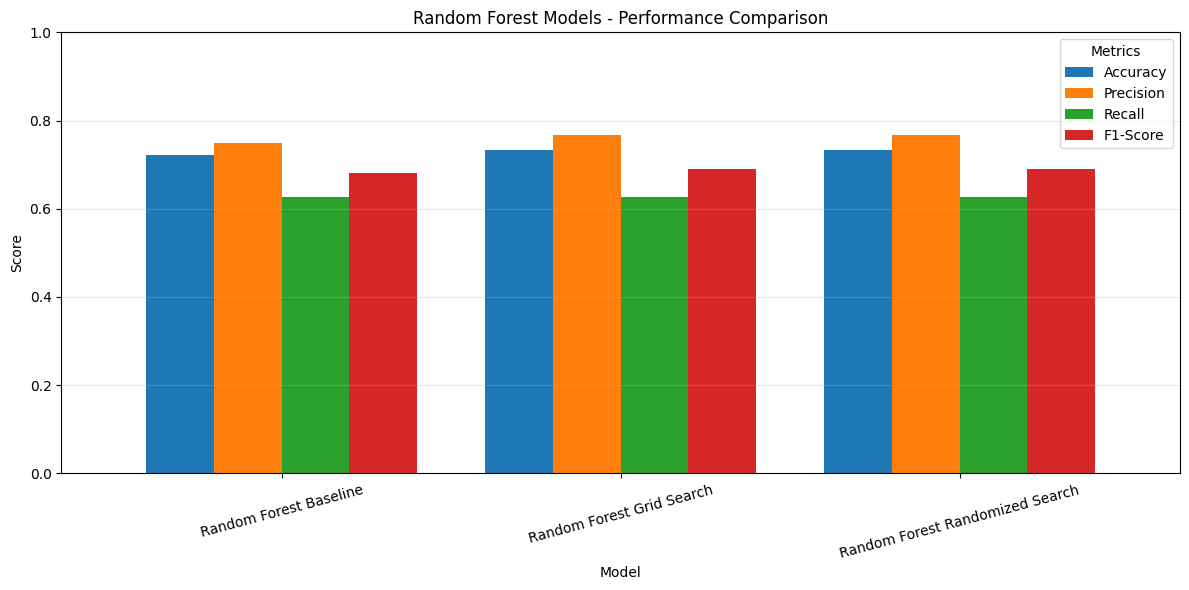

In [7]:

comparison_metrics.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title("Random Forest Models - Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title="Metrics")
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


,Model,Search Time
1,Random Forest Grid Search,142.529841
2,Random Forest Randomized Search,76.610195


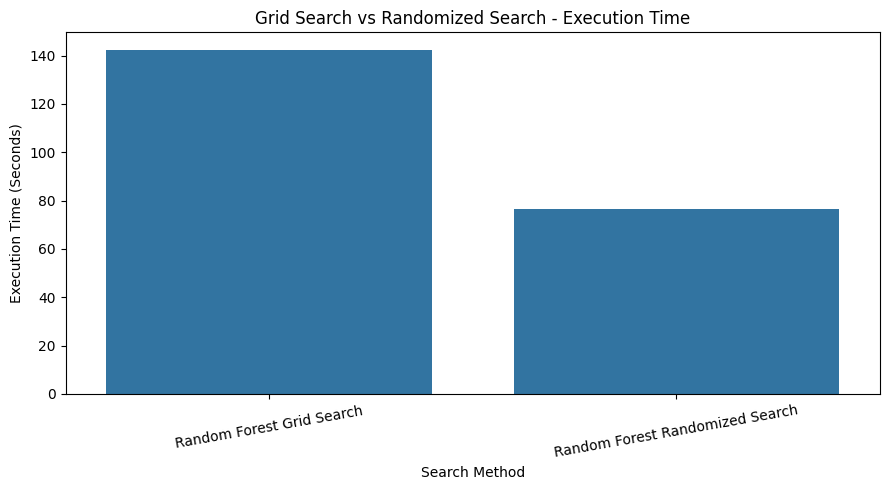

In [8]:

search_time_comparison = comparison_df[
    comparison_df['Model'] != 'Random Forest Baseline'
][['Model', 'Search Time']]

display(search_time_comparison)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=search_time_comparison,
    x='Model',
    y='Search Time'
)

plt.title("Grid Search vs Randomized Search - Execution Time")
plt.xlabel("Search Method")
plt.ylabel("Execution Time (Seconds)")
plt.xticks(rotation=10)

plt.tight_layout()
plt.show()


In [9]:

best_model = comparison_df.loc[
    comparison_df['F1-Score'].idxmax()
]

print("Best Model:")
print(best_model['Model'])

print("\nBest Performance:")
print(f"Accuracy:  {best_model['Accuracy']:.4f}")
print(f"Precision: {best_model['Precision']:.4f}")
print(f"Recall:    {best_model['Recall']:.4f}")
print(f"F1-Score:  {best_model['F1-Score']:.4f}")


Best Model:
Random Forest Grid Search

Best Performance:
Accuracy:  0.7326
Precision: 0.7665
Recall:    0.6267
F1-Score:  0.6895


In [10]:

output_dir = "/kaggle/working/final_comparison"
os.makedirs(output_dir, exist_ok=True)

comparison_df.to_csv(
    f"{output_dir}/final_model_comparison.csv",
    index=False
)

comparison_metrics.to_csv(
    f"{output_dir}/performance_comparison.csv"
)

print("Final comparison saved successfully!")


Final comparison saved successfully!


# Conclusion

In this project, three Random Forest classification approaches were implemented and evaluated using the Bank Marketing dataset:

1. Random Forest Baseline
2. Random Forest with GridSearchCV
3. Random Forest with RandomizedSearchCV

The Baseline model achieved an Accuracy of 72.28% and an F1-Score of 68.14%.

Grid Search improved the Accuracy to 73.26% and the F1-Score to 68.95%. It identified the following best hyperparameters:

- n_estimators = 200
- max_depth = 20
- max_features = sqrt
- min_samples_split = 5
- criterion = gini

Randomized Search achieved exactly the same test performance and identified the same best hyperparameter combination. However, it completed the search in 77.46 seconds compared with 94.06 seconds for Grid Search.

Therefore, Randomized Search was more time-efficient in this experiment, while both search methods achieved identical predictive performance.

Overall, hyperparameter tuning improved the Random Forest model compared with its default configuration, although the improvement was relatively modest.